# Combined M–c + Magnitude-Gap Recovery — Triaxial NFW + Miscentering

Simultaneously recovers the mass–concentration relation parameters
$(c_0, \alpha, \beta)$ **and** the magnitude-gap concentration slope $\gamma$
from un-stacked per-cluster $\Delta\Sigma$ profiles simulated with **triaxial NFW
shear** (random CDM-like axis ratios, isotropic line-of-sight orientations)
**and simulated miscentering**.

The miscentering model:
- A fraction $f_{\rm cen}$ of clusters are correctly centred.
- The remaining fraction $(1 - f_{\rm cen})$ have an offset drawn from a
  **Rayleigh distribution** with scale parameter $\sigma_{\rm off}$ [Mpc/$h$].

The combined parametric concentration is:

$$
\log_{10} c = \log_{10} c_0
  + \alpha\,(\log_{10} M - 14)
  + \beta\,\log_{10}\!\frac{1+z}{1+z_{\rm ref}}
  + \gamma\,\log_{10}\!\frac{\Delta m}{\Delta m_{\rm ref}}
$$

Miscentering is applied **only to the simulation** (the lensing measurement centre
is displaced from the true NFW centre).  The forward model remains spherical NFW
with no miscentering correction — the test probes how miscentering biases the
recovered parameters.

**Bias suppression**: `scatter_logc=0` and `poisson_richness=False` eliminate Jensen
and errors-in-variables biases, so residual biases come from triaxiality and
miscentering alone.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from astropy.table import Table

from destacking.simulation import generate_truth_catalog, make_test_data
from destacking.fitting import run_sampler_combined
from destacking.relations import c_DuttonMaccio
from destacking.model import _MC_M_PIVOT_LOG, _MC_Z_REF

from xlensing.sims import (
    make_simple_random_cat,
    apply_triaxial_NFW_shear_region,
    r_vir,
    project_ellipsoid,
)
from xlensing.data import metacal_cluster_lensing, signal
import ngmix

try:
    import corner
except ImportError:
    corner = None

try:
    from tqdm.auto import tqdm
except ImportError:
    def tqdm(it, **kwargs): return it

Lookup tables loaded!


## Parameters

In [2]:
N_CLUSTERS   = 5000          # number of clusters
TRUE_GAMMA   = 0.2          # gamma [dex/dex]: d(log10 c)/d(log10(delta_m/delta_m_ref))
DELTA_M_REF  = 0.1          # reference magnitude gap [mag]
RADII        = np.logspace(-0.8, 0.8, 12)   # projected radii [Mpc]
SEED         = None

# ── Miscentering model ──
F_CEN          = 1.0   # fraction of correctly centred clusters
SIGMA_OFF_MPC_H = 0.32  # Rayleigh scale for miscentred offsets [Mpc/h]

# ── Galaxy survey parameters ──
DENSITY         = 30
WIDTH_RAD       = 0.006     # field half-width [rad] ≈ ±20 arcmin
Z_SRC_RANGE     = (0.4, 1.5)
SHAPE_NOISE     = 0.27
NOISE_FLOOR_COV = 1e4       # [(M_sun/pc²)²]

# Bin limits
log_r  = np.log10(RADII)
dlog   = np.diff(log_r)[0]
edges  = np.logspace(log_r[0] - dlog/2, log_r[-1] + dlog/2, len(RADII) + 1)
bin_limits = np.column_stack([edges[:-1], edges[1:]])
N_BINS = len(RADII)

print(f'TRUE_GAMMA  = {TRUE_GAMMA}')
print(f'DELTA_M_REF = {DELTA_M_REF} mag')
print(f'F_CEN       = {F_CEN}  ({100*(1-F_CEN):.0f}% miscentred)')
print(f'SIGMA_OFF   = {SIGMA_OFF_MPC_H} Mpc/h')
print(f'M_pivot_log = {_MC_M_PIVOT_LOG},  z_ref = {_MC_Z_REF}')


TRUE_GAMMA  = 0.2
DELTA_M_REF = 0.1 mag
F_CEN       = 1.0  (0% miscentred)
SIGMA_OFF   = 0.32 Mpc/h
M_pivot_log = 14.0,  z_ref = 0.35


## 1 — Generate truth catalog

### Why `delta_m_gamma` cannot be used directly

`c_DuttonMaccio(z, M, c=c_param)` evaluates the DM14 formula as

$$\log_{10}c = a(z) + b(z)\,\log_{10}\!\frac{M}{c_{\rm param}\cdot10^{12}\,M_\odot}$$

so `c_param` **divides the pivot mass**, not the concentration.  Setting
`c_param = (\Delta m/\Delta m_{\rm ref})^\gamma` yields a log-space concentration
effect of only $|b(z)|\cdot\gamma \approx 0.10\,\gamma$, not $\gamma$ itself.

The forward model treats `gamma` as the full slope
$\mathrm{d}\log_{10}c\,/\,\mathrm{d}\log_{10}(\Delta m/\Delta m_{\rm ref})$.
To match this, the magnitude-gap scaling is applied as a **direct multiplicative
factor** on the base DM14 concentration:

$$\log_{10}c_{\rm truth} = \log_{10}c_{\rm DM}(z,M) + \gamma\,\log_{10}\!\frac{\Delta m}{\Delta m_{\rm ref}}$$

With this construction the OLS recovers $\gamma_{\rm OLS}\approx\gamma_{\rm true}$.

In [3]:
# Generate base concentrations from the DM relation (no gamma yet)
truth = generate_truth_catalog(
    N_CLUSTERS,
    z_range=(0.2, 0.6),
    logM_range=(13.5, 15.0),
    delta_m_gamma=0.0,   # gamma applied directly below
    scatter_logc=0.0,
    seed=SEED,
)

# Apply gamma as a direct log10(c) shift in log10(delta_m/delta_m_ref) space,
# matching the forward_model_combined parametrization exactly.
dm_s     = np.asarray(truth['delta_m'])
logdm_s  = np.log10(np.maximum(dm_s, 1e-6) / DELTA_M_REF)
truth['concentration'] = np.asarray(truth['concentration']) * 10.0 ** (TRUE_GAMMA * logdm_s)

# Extract truth parameters by OLS of log10(c) against model basis
logM_s  = np.log10(truth['M_halo'])
logc_s  = np.log10(truth['concentration'])
logz1_s = np.log10((1.0 + truth['z']) / (1.0 + _MC_Z_REF))

X = np.column_stack([
    np.ones(N_CLUSTERS),
    logM_s - _MC_M_PIVOT_LOG,
    logz1_s,
    logdm_s,              # gamma regressor is log10(delta_m / delta_m_ref)
])
coeffs, *_ = np.linalg.lstsq(X, logc_s, rcond=None)
logc0_true, alpha_true, beta_true, gamma_true = coeffs
c0_true = 10.0 ** logc0_true

print(f'Saved {N_CLUSTERS} clusters')
print(f'Truth:  c0={c0_true:.3f},  alpha={alpha_true:.4f},'
      f'  beta={beta_true:.4f},  gamma={gamma_true:.4f}')
print(f'(gamma_true should be ≈ TRUE_GAMMA = {TRUE_GAMMA})')
truth[:5]

Saved 5000 clusters
Truth:  c0=4.566,  alpha=-0.0909,  beta=-0.4686,  gamma=0.2000
(gamma_true should be ≈ TRUE_GAMMA = 0.2)


z,M_halo,concentration,M_BCG,L_BCG,L_brightest_sat,delta_m,N_sat
float64,float64,float64,float64,float64,float64,float64,int64
0.511670028511797,204259320282283.34,3.634801112382012,447392489012.46826,3752808676.6350513,3562482057.8288574,0.056509345786668046,41
0.3223943996674784,42073731206129.76,6.021312128743226,323322565773.77295,2575236591.7409596,2037949846.9075775,0.25405910662393383,10
0.3548773325958342,46449385202963.586,3.8345951339432256,334266232377.89545,2685165291.2815084,2613256145.1234226,0.029472611233925576,14
0.533866509959799,40061074799280.555,2.7197109187254926,232116951809.40704,1621221110.1998415,1611191684.9922144,0.006737595533362128,7
0.3970487001577435,47419031827119.67,7.0574529632139065,221676190567.09952,1509154768.4881437,809839986.2163447,0.6758364096322329,17


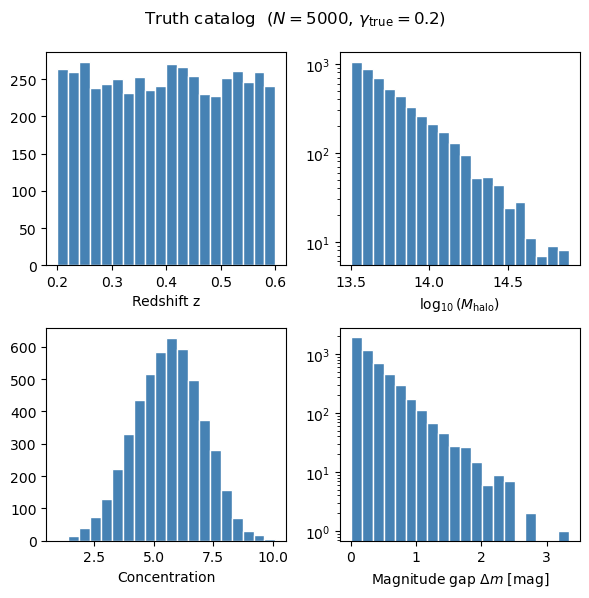

In [4]:
fig, axes = plt.subplots(2,2, figsize=(6,6))

axes[0,0].hist(truth['z'], bins=20, color='steelblue', edgecolor='white')
axes[0,0].set_xlabel('Redshift z')

axes[0,1].hist(np.log10(truth['M_halo']), bins=20, color='steelblue', edgecolor='white')
axes[0,1].set_xlabel(r'$\log_{10}(M_{\rm halo})$')
axes[0,1].set_yscale('log')

axes[1,0].hist(truth['concentration'], bins=20, color='steelblue', edgecolor='white')
axes[1,0].set_xlabel('Concentration')

axes[1,1].hist(truth['delta_m'], bins=20, color='steelblue', edgecolor='white')
axes[1,1].set_xlabel(r'Magnitude gap $\Delta m$ [mag]')
axes[1,1].set_yscale('log')

#for ax in axes: ax.set_ylabel('Count')
plt.suptitle(
    rf'Truth catalog  ($N={N_CLUSTERS}$, $\gamma_{{\rm true}}={TRUE_GAMMA}$)',
    y=.99,
)
plt.tight_layout(); plt.show()

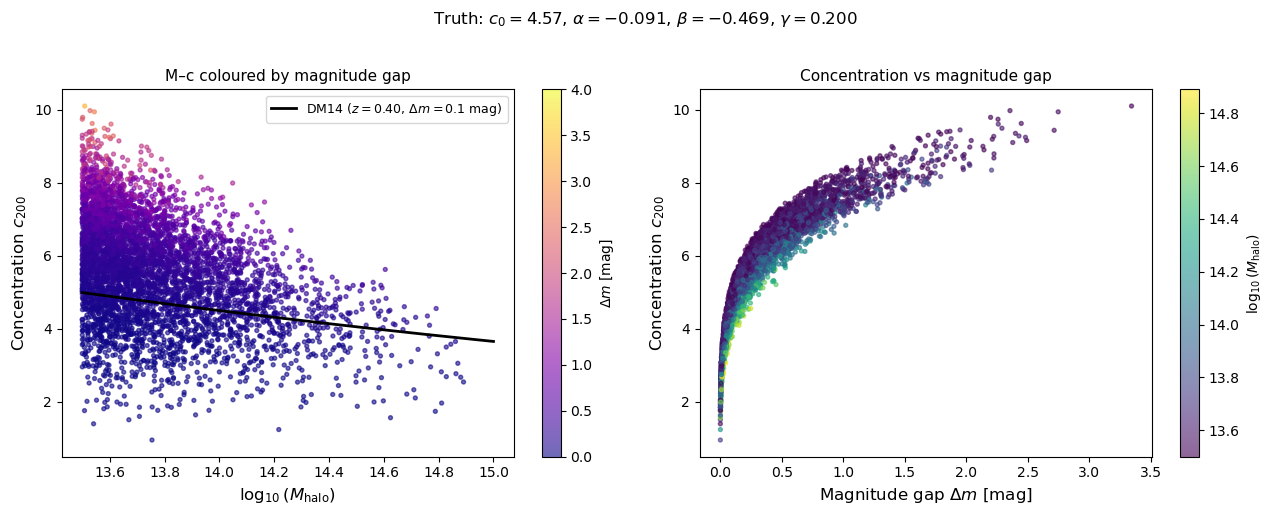

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# M–c scatter coloured by delta_m
ax = axes[0]
sc = ax.scatter(logM_s, truth['concentration'],
                c=truth['delta_m'], cmap='plasma', s=8, alpha=0.6,
                vmin=0, vmax=4, rasterized=True)
plt.colorbar(sc, ax=ax, label=r'$\Delta m$ [mag]')
z_med  = float(np.median(truth['z']))
M_grid = np.logspace(13.5, 15.0, 200)
C_dm0  = c_DuttonMaccio(z_med * np.ones(200), M_grid, c=1.0)
ax.plot(np.log10(M_grid), C_dm0, 'k-', lw=2,
        label=rf'DM14 ($z={z_med:.2f}$, $\Delta m={DELTA_M_REF}$ mag)')
ax.set_xlabel(r'$\log_{10}(M_{\rm halo})$', fontsize=12)
ax.set_ylabel(r'Concentration $c_{200}$', fontsize=12)
ax.set_title('M–c coloured by magnitude gap', fontsize=11)
ax.legend(fontsize=9)

# c vs delta_m coloured by log M
ax = axes[1]
sc2 = ax.scatter(truth['delta_m'], truth['concentration'],
                 c=logM_s, cmap='viridis', s=8, alpha=0.6, rasterized=True)
plt.colorbar(sc2, ax=ax, label=r'$\log_{10}(M_{\rm halo})$')
ax.set_xlabel(r'Magnitude gap $\Delta m$ [mag]', fontsize=12)
ax.set_ylabel(r'Concentration $c_{200}$', fontsize=12)
ax.set_title(r'Concentration vs magnitude gap', fontsize=11)

plt.suptitle(
    rf'Truth: $c_0={c0_true:.2f}$, $\alpha={alpha_true:.3f}$, '
    rf'$\beta={beta_true:.3f}$, $\gamma={gamma_true:.3f}$',
    y=1.02, fontsize=12,
)
plt.tight_layout(); plt.show()

## 2 — Triaxial shapes

Projecting triaxial ellipsoids...
Projected q_min/q_maj: median=0.68, range [0.30, 1.00]


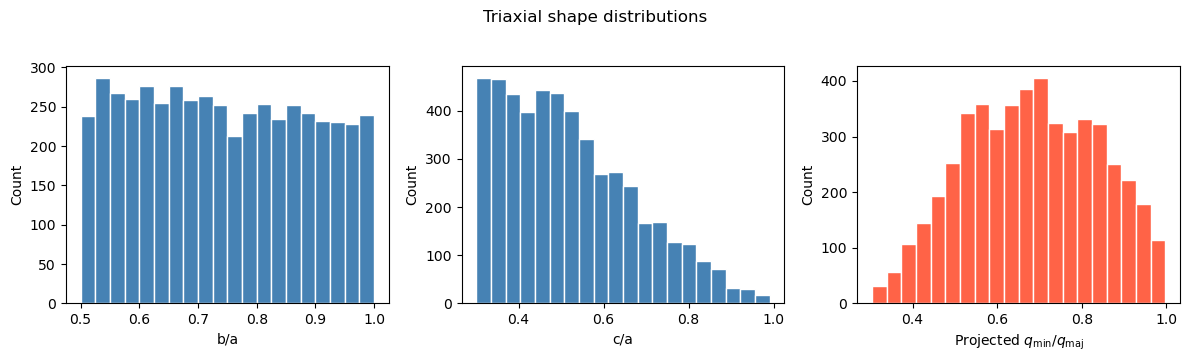

In [6]:
_seed_tri = None if SEED is None else SEED + 10
rng_tri = np.random.default_rng(_seed_tri)

r_vir_vals = np.array([
    r_vir(float(z), float(M))
    for z, M in zip(truth['z'], truth['M_halo'])
])

q_ba = rng_tri.uniform(0.5, 1.0, N_CLUSTERS)
q_ca = rng_tri.uniform(0.3, q_ba)

theta_los_arr = np.arccos(rng_tri.uniform(0.0, 1.0, N_CLUSTERS))
phi_los_arr   = rng_tri.uniform(0.0, 2 * np.pi, N_CLUSTERS)

print('Projecting triaxial ellipsoids...')
q_maj_arr = np.zeros(N_CLUSTERS)
q_min_arr = np.zeros(N_CLUSTERS)
pa_arr    = np.zeros(N_CLUSTERS)
for i in range(N_CLUSTERS):
    a = r_vir_vals[i]
    b, c = q_ba[i] * a, q_ca[i] * a
    q_maj_arr[i], q_min_arr[i], pa_arr[i] = project_ellipsoid(
        a, b, c, theta_los_arr[i], phi_los_arr[i]
    )

print(f'Projected q_min/q_maj: '
      f'median={np.median(q_min_arr/q_maj_arr):.2f}, '
      f'range [{(q_min_arr/q_maj_arr).min():.2f}, {(q_min_arr/q_maj_arr).max():.2f}]')

fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
axes[0].hist(q_ba, bins=20, color='steelblue', edgecolor='white')
axes[0].set_xlabel('b/a')
axes[1].hist(q_ca, bins=20, color='steelblue', edgecolor='white')
axes[1].set_xlabel('c/a')
axes[2].hist(q_min_arr / q_maj_arr, bins=20, color='tomato', edgecolor='white')
axes[2].set_xlabel(r'Projected $q_{\rm min}/q_{\rm maj}$')
for ax in axes: ax.set_ylabel('Count')
plt.suptitle('Triaxial shape distributions', y=1.02)
plt.tight_layout(); plt.show()


## 3 — Miscentering offsets

A fraction $1 - f_{\rm cen}$ of clusters are assigned a random positional offset
between the true NFW centre and the measured lensing centre.  The offset magnitude
is drawn from a **Rayleigh distribution** with scale $\sigma_{\rm off}$:

$$
P(r) = \frac{r}{\sigma_{\rm off}^2}\,\exp\!\left(-\frac{r^2}{2\sigma_{\rm off}^2}\right),
\quad r \ge 0,
$$

corresponding to the length of a 2D isotropic Gaussian displacement with per-component
dispersion $\sigma_{\rm off}$.  The offset direction is drawn isotropically on the sky.

The offsets are computed in physical Mpc at the cluster redshift and converted to
angular units (radians) per cluster.  During the lensing measurement the centring
position passed to `metacal_cluster_lensing` is displaced by this offset, while the
true NFW shear is still applied around $(0, 0)$.


Miscentred clusters : 0 / 5000 (0.0%)
sigma_off           : 0.32 Mpc/h  =  0.473 Mpc
Mean Rayleigh offset: 0.593 Mpc  (sigma_off * sqrt(pi/2))


/home/andre/miniconda3/lib/python3.12/site-packages/numpy/lib/_histograms_impl.py:901: RuntimeWarning: invalid value encountered in divide
  return n/db/n.sum(), bin_edges


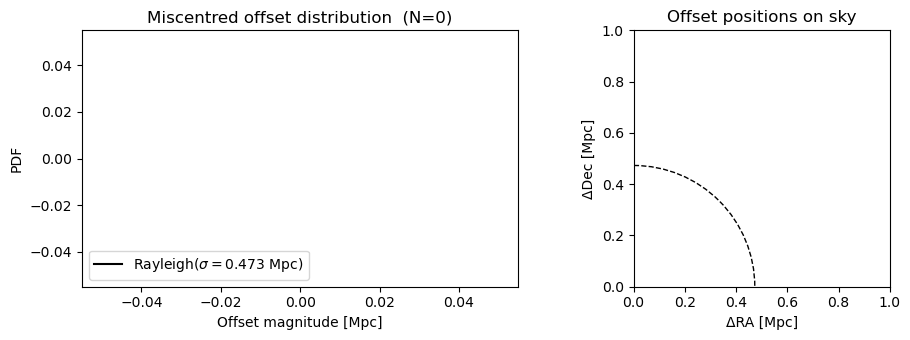

In [7]:
from astropy.cosmology import Planck18 as _planck18

h = float(_planck18.h)                     # ≈ 0.674
SIGMA_OFF_MPC = SIGMA_OFF_MPC_H / h        # convert Mpc/h → physical Mpc

_seed_mis = None if SEED is None else SEED + 20
rng_mis = np.random.default_rng(_seed_mis)

# Bernoulli: 1 = miscentred
is_miscentered = rng_mis.uniform(0, 1, N_CLUSTERS) > F_CEN

# Rayleigh offset magnitudes (physical Mpc); centred clusters get 0
off_mag_mpc = np.where(
    is_miscentered,
    rng_mis.rayleigh(scale=SIGMA_OFF_MPC, size=N_CLUSTERS),
    0.0,
)
phi_mis = rng_mis.uniform(0, 2 * np.pi, N_CLUSTERS)

n_mis = int(is_miscentered.sum())
print(f'Miscentred clusters : {n_mis} / {N_CLUSTERS} ({100*n_mis/N_CLUSTERS:.1f}%)')
print(f'sigma_off           : {SIGMA_OFF_MPC_H} Mpc/h  =  {SIGMA_OFF_MPC:.3f} Mpc')
print(f'Mean Rayleigh offset: {SIGMA_OFF_MPC * np.sqrt(np.pi/2):.3f} Mpc'
      f'  (sigma_off * sqrt(pi/2))')
if n_mis > 0:
    print(f'Median offset (miscentred sample): '
          f'{np.median(off_mag_mpc[is_miscentered]):.3f} Mpc')

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].hist(off_mag_mpc[is_miscentered], bins=25,
             color='tomato', edgecolor='white', density=True)
r_grid = np.linspace(0, off_mag_mpc.max() * 1.1, 300)
pdf_ray = r_grid / SIGMA_OFF_MPC**2 * np.exp(-r_grid**2 / (2 * SIGMA_OFF_MPC**2))
axes[0].plot(r_grid, pdf_ray, 'k-', lw=1.5, label=rf'Rayleigh($\sigma={SIGMA_OFF_MPC:.3f}$ Mpc)')
axes[0].set_xlabel('Offset magnitude [Mpc]')
axes[0].set_ylabel('PDF')
axes[0].set_title(f'Miscentred offset distribution  (N={n_mis})')
axes[0].legend()

theta_plot = np.linspace(0, 2*np.pi, 200)
for r_i, ph_i in zip(off_mag_mpc[is_miscentered][:200],
                     phi_mis[is_miscentered][:200]):
    axes[1].plot(r_i * np.cos(ph_i), r_i * np.sin(ph_i),
                 'o', color='tomato', ms=2, alpha=0.4)
axes[1].add_patch(plt.Circle((0,0), SIGMA_OFF_MPC, fill=False, ls='--', color='k', lw=1))
axes[1].set_aspect('equal')
axes[1].set_xlabel('ΔRA [Mpc]')
axes[1].set_ylabel('ΔDec [Mpc]')
axes[1].set_title('Offset positions on sky')
plt.tight_layout(); plt.show()


## 4 — Simulate triaxial NFW lensing with miscentering

In [8]:
%%time
import multiprocess as mp
from scipy.interpolate import interp1d
import xlensing.cosmo as _xlc
import xlensing.sims as _xlsims

# ── DA spline patch ────────────────────────────────────────────────────────
_z_tab    = np.linspace(0.0, 3.0, 5000)
_chi_tab  = _xlc.cosmology.comoving_distance(_z_tab).value
_chi_of_z = interp1d(_z_tab, _chi_tab, kind='linear',
                     bounds_error=False, fill_value='extrapolate')

def _DA_fast(z1, z2):
    z2_a = np.atleast_1d(np.asarray(z2, dtype=float))
    res  = (_chi_of_z(z2_a) - float(_chi_of_z(float(z1)))) / (1.0 + z2_a)
    return float(res[0]) if np.ndim(z2) == 0 else res

_xlc.DA    = _DA_fast
_xlsims.DA = _DA_fast

# ── Background source field ────────────────────────────────────────────────
rng_base = np.random.default_rng(99)
base_cat = make_simple_random_cat(DENSITY, WIDTH_RAD, Z_SRC_RANGE,
                                  shape_noise=0.0, seed=0).T
N_GALS   = len(base_cat)

sizes  = rng_base.lognormal(mean=np.log(0.5), sigma=0.5, size=N_GALS)
R_RESP = np.clip(1.0 - (sizes / 1.5) ** 2, 0.05, 0.99)
base_cat[:, 5] = R_RESP
base_cat[:, 6] = 0.0
base_cat[:, 7] = 0.0
base_cat[:, 8] = R_RESP
print(f'Source field: {N_GALS} galaxies, half-width {WIDTH_RAD} rad')

# ── Per-cluster worker ─────────────────────────────────────────────────────
def _process_cluster(i):
    z_i = float(truth['z'][i])
    M_i = float(truth['M_halo'][i])
    c_i = float(truth['concentration'][i])
    a_i = r_vir_vals[i]

    rng_i  = np.random.default_rng(1000 + i)
    sp_i   = ngmix.priors.shape.GPriorBA(sigma=SHAPE_NOISE, rng=rng_i)
    e1, e2 = sp_i.sample2d(N_GALS)

    gal_i = base_cat.copy()
    gal_i[:, 3] = e1
    gal_i[:, 4] = e2

    mc_mask = gal_i[:, 2] > 1.1 * z_i + 0.2
    gal_mc  = gal_i[mc_mask]
    if len(gal_mc) < 20:
        return i, None, None

    # Apply triaxial NFW shear around the TRUE cluster centre (0, 0)
    cluster_arr = [0., 0., z_i, M_i, c_i,
                   a_i, q_ba[i] * a_i, q_ca[i] * a_i,
                   theta_los_arr[i], phi_los_arr[i]]
    gal_sheared = apply_triaxial_NFW_shear_region(cluster_arr, gal_mc)

    sources_mc = gal_sheared[:, [0, 1, 2, 3, 4, 9, 5, 6, 7, 8]]
    radius_mpc = WIDTH_RAD * _DA_fast(0, z_i)

    # Miscentering: measure the profile around the OFFSET centre, not (0,0).
    # The offset is pre-computed in physical Mpc; convert to radians here.
    DA_i      = _DA_fast(0, z_i)                    # angular diameter distance [Mpc]
    off_rad_i = off_mag_mpc[i] / DA_i               # angular offset [rad]
    cen_ra_i  = off_rad_i * np.cos(phi_mis[i])      # RA  offset of "observed" centre
    cen_dec_i = off_rad_i * np.sin(phi_mis[i])      # Dec offset of "observed" centre

    bg = metacal_cluster_lensing((cen_ra_i, cen_dec_i, z_i), sources_mc.T, radius_mpc)
    if bg['Count'] < 20:
        return i, None, None

    stake = np.array([
        bg['Critical Density'], bg['Tangential Shear'], bg['Cross Shear'],
        bg['Weights'], bg['Radial Distance'], bg['Mult. Bias'],
    ])
    sig_t, _ = signal(stake, bin_limits)
    dv = np.nan_to_num(sig_t, nan=0.0)

    R      = bg['Radial Distance']
    in_bin = (R[:, None] > bin_limits[:, 0]) & (R[:, None] < bin_limits[:, 1])
    cov_d  = np.full(N_BINS, NOISE_FLOOR_COV)
    for b in range(N_BINS):
        m   = in_bin[:, b]
        n_b = m.sum()
        if n_b >= 5:
            cov_d[b] = (SHAPE_NOISE * bg['Critical Density'][m].mean()
                        / np.sqrt(n_b)) ** 2

    return i, dv, cov_d

# ── Output arrays ──────────────────────────────────────────────────────────
data_vectors = np.zeros((N_CLUSTERS, N_BINS))
cov_matrices = np.full((N_CLUSTERS, N_BINS, N_BINS), 0.0)
for i in range(N_CLUSTERS):
    np.fill_diagonal(cov_matrices[i], NOISE_FLOOR_COV)

# ── Parallel dispatch ──────────────────────────────────────────────────────
N_WORKERS = 15
with mp.Pool(N_WORKERS) as pool:
    for idx, dv, cov_d in tqdm(
        pool.imap(_process_cluster, range(N_CLUSTERS), chunksize=10),
        total=N_CLUSTERS, desc='Triaxial + miscentering lensing',
    ):
        if dv is not None:
            data_vectors[idx] = dv
            np.fill_diagonal(cov_matrices[idx], cov_d)

non_empty = (np.diagonal(cov_matrices, axis1=1, axis2=2) < NOISE_FLOOR_COV).sum(1).mean()
print(f'\nNon-empty bins per cluster: {non_empty:.1f} / {N_BINS}')


Source field: 12764 galaxies, half-width 0.006 rad


Triaxial + miscentering lensing:   0%|          | 0/5000 [00:00<?, ?it/s]

/home/andre/github/xlensing/xlensing/data.py:252: RuntimeWarning: invalid value encountered in divide
  return num_t / denom_K, num_x / denom_K
/home/andre/github/xlensing/xlensing/data.py:252: RuntimeWarning: invalid value encountered in divide
  return num_t / denom_K, num_x / denom_K
/home/andre/github/xlensing/xlensing/data.py:252: RuntimeWarning: invalid value encountered in divide
  return num_t / denom_K, num_x / denom_K
/home/andre/github/xlensing/xlensing/data.py:252: RuntimeWarning: invalid value encountered in divide
  return num_t / denom_K, num_x / denom_K
/home/andre/github/xlensing/xlensing/data.py:252: RuntimeWarning: invalid value encountered in divide
  return num_t / denom_K, num_x / denom_K
/home/andre/github/xlensing/xlensing/data.py:252: RuntimeWarning: invalid value encountered in divide
  return num_t / denom_K, num_x / denom_K
/home/andre/github/xlensing/xlensing/data.py:252: RuntimeWarning: invalid value encountered in divide
  return num_t / denom_K, num_x / 


Non-empty bins per cluster: 6.8 / 12
CPU times: user 1.32 s, sys: 615 ms, total: 1.94 s
Wall time: 29.1 s


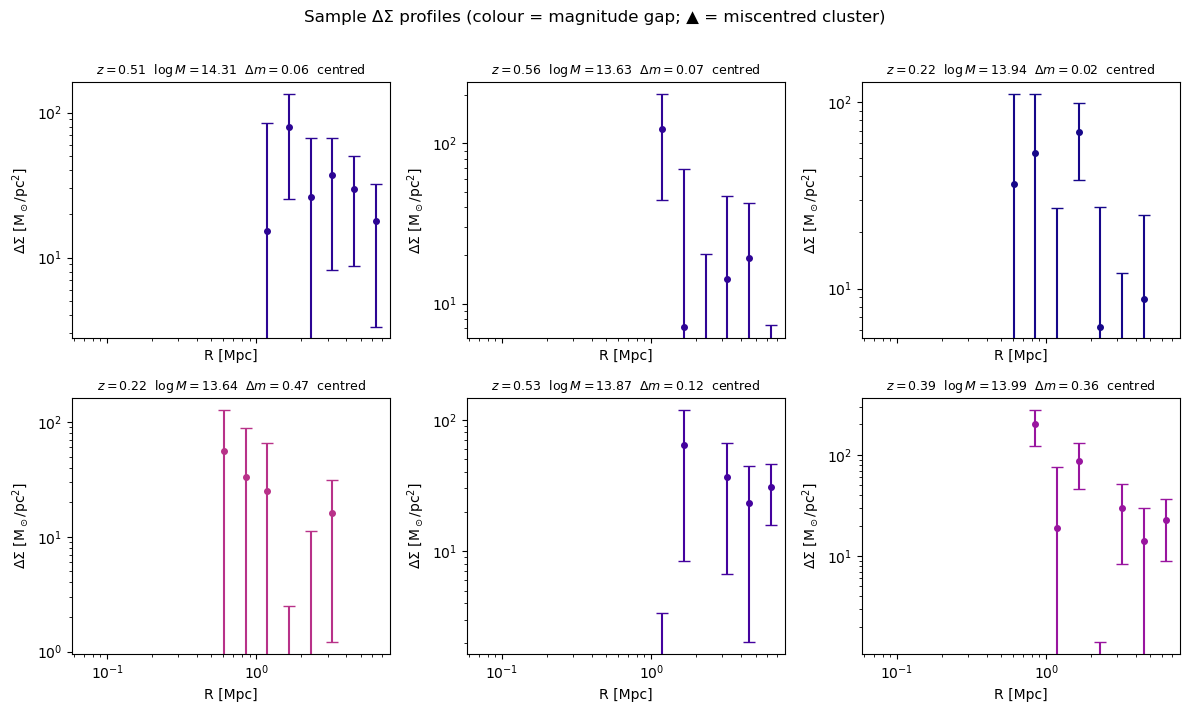

In [9]:
# Sanity check: six example profiles, coloured by delta_m
# Circles = centred clusters, triangles = miscentred clusters
idx = np.round(np.linspace(0, N_CLUSTERS - 1, 6)).astype(int)
fig, axes = plt.subplots(2, 3, figsize=(12, 7), sharex=True)

cmap_dm = plt.cm.plasma
dm_all  = np.asarray(truth['delta_m'])
vmin, vmax = 0.0, float(np.nanpercentile(dm_all, 95))

for ax, i in zip(axes.ravel(), idx):
    errs = np.sqrt(np.diag(cov_matrices[i]))
    real = errs < np.sqrt(NOISE_FLOOR_COV)
    dm_i = float(truth['delta_m'][i])
    col  = cmap_dm((dm_i - vmin) / (vmax - vmin))
    marker = '^' if is_miscentered[i] else 'o'
    ax.errorbar(RADII[real], data_vectors[i, real], yerr=errs[real],
                fmt=marker, markersize=4, capsize=4, color=col)
    ax.set_xscale('log'); ax.set_yscale('log')
    mis_str = f'off={off_mag_mpc[i]:.2f} Mpc' if is_miscentered[i] else 'centred'
    ax.set_title(
        rf'$z={truth["z"][i]:.2f}$  '
        rf'$\log M={np.log10(truth["M_halo"][i]):.2f}$  '
        rf'$\Delta m={dm_i:.2f}$  {mis_str}',
        fontsize=9,
    )
    ax.set_xlabel('R [Mpc]')
    ax.set_ylabel(r'$\Delta\Sigma$ [M$_\odot$/pc$^2$]')

plt.suptitle(
    'Sample ΔΣ profiles (colour = magnitude gap; ▲ = miscentred cluster)',
    y=1.01,
)
plt.tight_layout(); plt.show()


## 5 — Cluster observable table

Richness from the deterministic McClintock+18 inversion of the true mass
(`poisson_richness=False`) — no Eddington bias.  The `delta_m` column from the
truth catalog is passed through for the gamma term in the forward model.


In [10]:
_seed_obs = None if SEED is None else SEED + 1

cluster_obs, _, _ = make_test_data(
    truth, RADII,
    fractional_noise=0.2,
    poisson_richness=False,
    seed=_seed_obs,
)

print(f'Columns: {cluster_obs.colnames}')
print(f'Richness:  {cluster_obs["Lambda"].min():.1f} – {cluster_obs["Lambda"].max():.1f}')
print(f'delta_m:   {cluster_obs["delta_m"].min():.2f} – {cluster_obs["delta_m"].max():.2f}')
cluster_obs[:5]


Columns: ['z', 'Lambda', 'delta_m']
Richness:  6.6 – 84.2
delta_m:   0.00 – 3.34


z,Lambda,delta_m
float64,float64,float64
0.511670028511797,32.11259312775792,0.056509345786668046
0.3223943996674784,9.042085123700515,0.25405910662393383
0.3548773325958342,9.935282572287372,0.029472611233925576
0.533866509959799,9.750580746431957,0.006737595533362128
0.3970487001577435,10.341561038655039,0.6758364096322329


## 6 — Run the combined sampler

Fits $(c_0, \alpha, \beta, \gamma, \log M_{\rm norm})$ jointly against the
triaxially-simulated, miscentred $\Delta\Sigma$ profiles.
The forward model is **spherical NFW with no miscentering correction** — the
analysis is deliberately blind to the simulated miscentering.


In [11]:
sampler = run_sampler_combined(
    cluster_obs,
    data_vectors,
    cov_matrices,
    RADII,
    c0_prior_loc=5.0,
    c0_prior_scale=5.0,
    alpha_prior_loc=0.0,
    alpha_prior_scale=0.5,
    beta_prior_loc=0.0,
    beta_prior_scale=1.0,
    gamma_range=(-1.0, 1.0),
    gamma_prior_sigma=0.5,
    delta_m_ref=DELTA_M_REF,
    fit_beta=True,
    n_live=400,
    pool=15,
    verbose=True,
)

Starting the nautilus sampler...
Please report issues at github.com/johannesulf/nautilus.
Status    | Bounds | Ellipses | Networks | Calls    | f_live | N_eff | log Z    
Finished  | 36     | 1        | 4        | 22155    | N/A    | 10054 | -398907.2


## 6 — Posterior analysis

In [12]:
points, log_w, log_l = sampler.posterior()
weights = np.exp(log_w - log_w.max())
weights /= weights.sum()

# Parameter order: c0, alpha, beta, gamma, log_M_norm
c0_s    = points[:, 0]
alpha_s = points[:, 1]
beta_s  = points[:, 2]
gamma_s = points[:, 3]
MN_s    = points[:, 4]

def wq(v, q):
    sorter = np.argsort(v)
    cs = np.cumsum(weights[sorter]) / weights.sum()
    return np.interp(q, cs, v[sorter])

truths_list = [c0_true, alpha_true, beta_true, gamma_true, 0.0]
names_list  = ['c0', 'alpha', 'beta', 'gamma', 'log_M_norm']
samples_list = [c0_s, alpha_s, beta_s, gamma_s, MN_s]

results = {}
print(f'{"param":<14} {"median":>10}  {"−1σ":>8}  {"+1σ":>8}  {"truth":>10}  {"bias":>8}')
print('-' * 65)
for name, samp, tv in zip(names_list, samples_list, truths_list):
    lo, md, hi = wq(samp, 0.16), wq(samp, 0.50), wq(samp, 0.84)
    sigma = (hi - lo) / 2
    bias  = (md - tv) / sigma if sigma > 0 else np.nan
    results[name] = (lo, md, hi, tv, bias)
    flag = '  ✓' if abs(bias) < 2 else '  BIASED'
    print(f'{name:<14} {md:>+10.4f}  {md-lo:>8.4f}  {hi-md:>8.4f}'
          f'  {tv:>+10.4f}  {bias:>+7.2f}σ{flag}')

param              median       −1σ       +1σ       truth      bias
-----------------------------------------------------------------
c0                +4.1052    0.1385    0.1432     +4.5662    -3.27σ  BIASED
alpha             -0.0459    0.0352    0.0343     -0.0909    +1.30σ  ✓
beta              -4.1766    0.3244    0.3173     -0.4686   -11.56σ  BIASED
gamma             +0.1201    0.0212    0.0211     +0.2000    -3.77σ  BIASED
log_M_norm        -0.0398    0.0135    0.0137     +0.0000    -2.93σ  BIASED


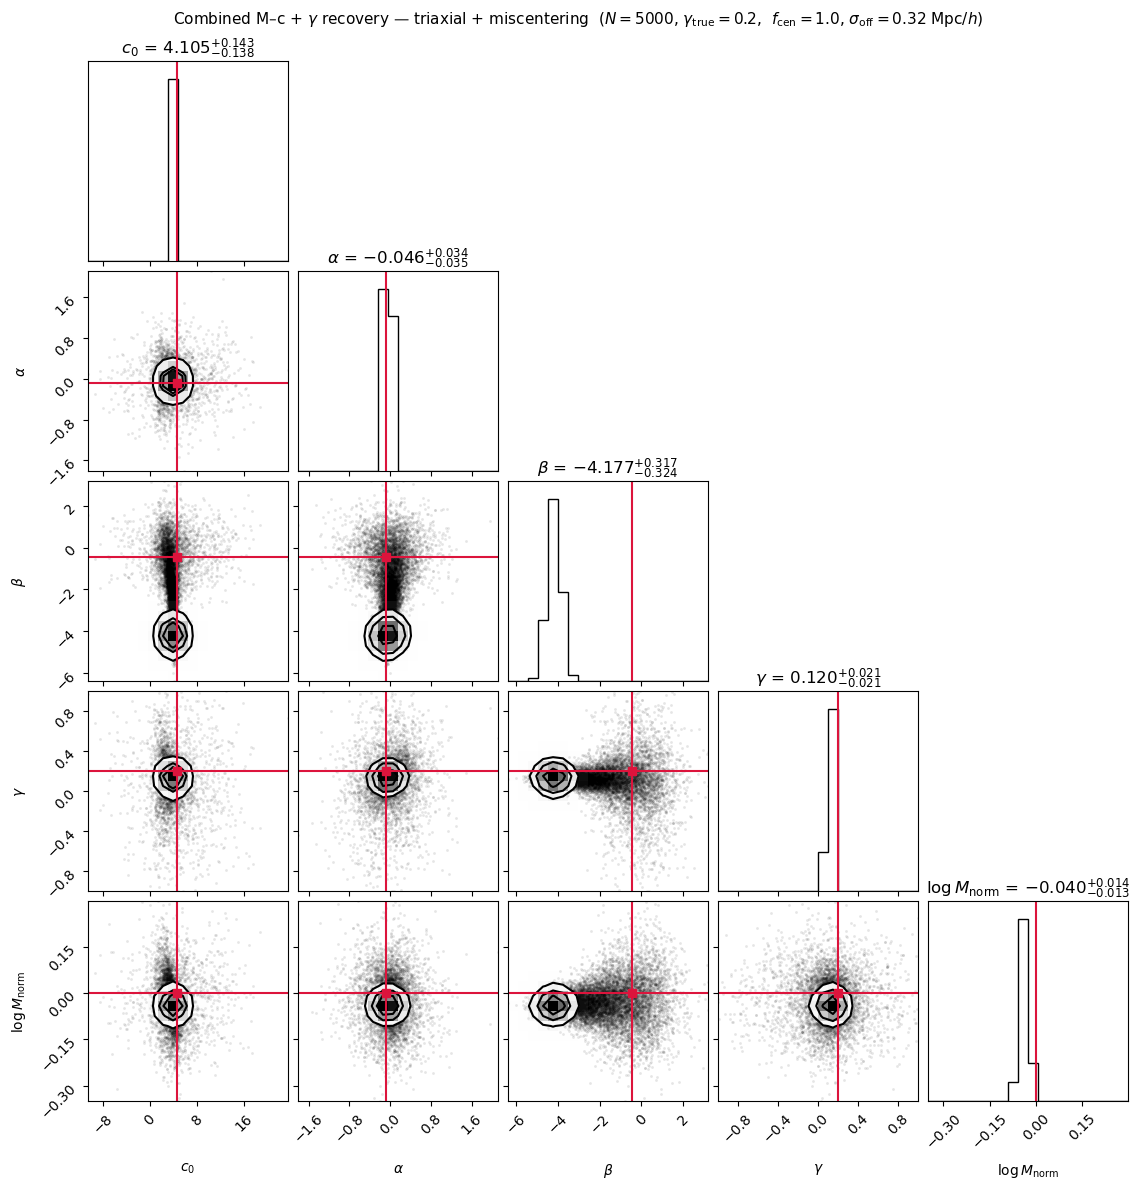

In [13]:
if corner is not None:
    labels = [
        r'$c_0$',
        r'$\alpha$',
        r'$\beta$',
        r'$\gamma$',
        r'$\log M_{\rm norm}$',
    ]
    fig = corner.corner(
        points,
        weights=weights,
        labels=labels,
        truths=truths_list,
        truth_color='crimson',
        show_titles=True,
        title_fmt='.3f',
        smooth=1.0,
    )
    plt.suptitle(
        rf'Combined M–c + $\gamma$ recovery — triaxial + miscentering'
        rf'  ($N={N_CLUSTERS}$, $\gamma_{{\rm true}}={TRUE_GAMMA}$,'
        rf'  $f_{{\rm cen}}={F_CEN}$, $\sigma_{{\rm off}}={SIGMA_OFF_MPC_H}$ Mpc/$h$)',
        y=1.01, fontsize=11,
    )
    plt.savefig('combined_posterior_triaxial_miscentering.png', dpi=150, bbox_inches='tight')
    plt.show()
else:
    print('Install corner for the triangle plot.')


## 7 — M–c recovery band at fixed magnitude gap

Shows posterior concentration bands at three representative $\Delta m$ values
against the DM14 truth curves.  The gamma term tilts the band relative to the
reference $\Delta m = \Delta m_{\rm ref}$ curve.

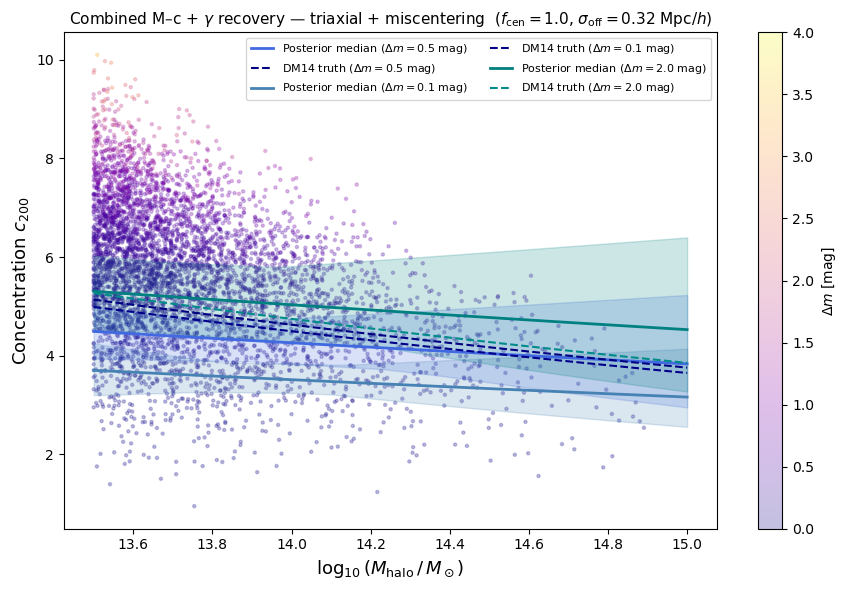

In [14]:
M_grid  = np.logspace(13.5, 15.0, 200)
logM_g  = np.log10(M_grid)
z_med   = float(np.median(truth['z']))
logz1_g = np.log10((1 + z_med) / (1 + _MC_Z_REF))

dm_show    = [0.5, DELTA_M_REF, 2.0]
colors     = ['royalblue', 'steelblue', 'teal']
colors_tru = ['navy', 'darkblue', 'darkcyan']

rng_plot = np.random.default_rng(0)
idx_band = rng_plot.choice(len(c0_s), size=300,
                           p=weights / weights.sum(), replace=True)

fig, ax = plt.subplots(figsize=(9, 6))

for dm_val, col, col_t in zip(dm_show, colors, colors_tru):
    log_dm_r = np.log10(max(dm_val, 1e-6) / DELTA_M_REF)
    label_dm = rf'$\Delta m = {dm_val:.1f}$ mag'

    C_band = np.array([
        10.0 ** (np.log10(c0_s[k])
                 + alpha_s[k] * (logM_g - _MC_M_PIVOT_LOG)
                 + beta_s[k]  * logz1_g
                 + gamma_s[k] * log_dm_r)
        for k in idx_band
    ])
    ax.fill_between(logM_g, C_band.min(0), C_band.max(0),
                    alpha=0.20, color=col)

    _, md_c, _, _, _ = results['c0']
    _, md_a, _, _, _ = results['alpha']
    _, md_b, _, _, _ = results['beta']
    _, md_g, _, _, _ = results['gamma']
    C_med = 10.0 ** (np.log10(md_c) + md_a * (logM_g - _MC_M_PIVOT_LOG)
                     + md_b * logz1_g + md_g * log_dm_r)
    ax.plot(logM_g, C_med, color=col, lw=2, label=f'Posterior median ({label_dm})')

    c_piv_true = 1.0 * (max(dm_val, 1e-6) / DELTA_M_REF) ** TRUE_GAMMA
    C_true = c_DuttonMaccio(z_med * np.ones(200), M_grid, c=c_piv_true)
    ax.plot(logM_g, C_true, '--', color=col_t, lw=1.5,
            label=f'DM14 truth ({label_dm})')

sc = ax.scatter(logM_s, truth['concentration'],
                c=truth['delta_m'], cmap='plasma', s=5, alpha=0.25,
                vmin=0, vmax=4, rasterized=True, zorder=0)
plt.colorbar(sc, ax=ax, label=r'$\Delta m$ [mag]')

ax.set_xlabel(r'$\log_{10}(M_{\rm halo}\,/\,M_\odot)$', fontsize=13)
ax.set_ylabel(r'Concentration $c_{200}$', fontsize=13)
ax.set_title(
    rf'Combined M–c + $\gamma$ recovery — triaxial + miscentering'
    rf'  ($f_{{\rm cen}}={F_CEN}$, $\sigma_{{\rm off}}={SIGMA_OFF_MPC_H}$ Mpc/$h$)',
    fontsize=11,
)
ax.legend(fontsize=8, ncol=2)
plt.tight_layout()
plt.savefig('combined_mc_recovery_triaxial_miscentering.png', dpi=150)
plt.show()


## 8 — Gamma marginal posterior

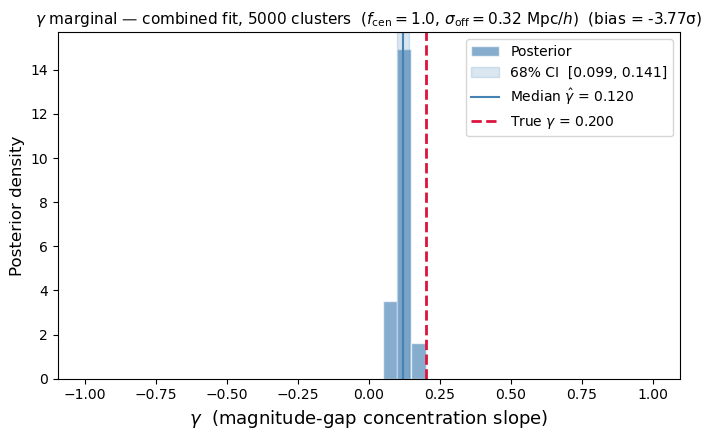


--- Final summary ---
  c0            : +4.1052  truth +4.5662  bias -3.27σ  [BIASED]
  alpha         : -0.0459  truth -0.0909  bias +1.30σ  [OK]
  beta          : -4.1766  truth -0.4686  bias -11.56σ  [BIASED]
  gamma         : +0.1201  truth +0.2000  bias -3.77σ  [BIASED]
  log_M_norm    : -0.0398  truth +0.0000  bias -2.93σ  [BIASED]


In [15]:
lo_g, md_g, hi_g, tv_g, bias_g = results['gamma']

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.hist(gamma_s, weights=weights, bins=40, density=True,
        color='steelblue', alpha=0.65, edgecolor='white', label='Posterior')
ax.axvspan(lo_g, hi_g, alpha=0.20, color='steelblue',
           label=rf'68% CI  [{lo_g:.3f}, {hi_g:.3f}]')
ax.axvline(md_g,   color='steelblue', lw=1.5, ls='-',
           label=rf'Median $\hat{{\gamma}}$ = {md_g:.3f}')
ax.axvline(tv_g,   color='crimson',   lw=2.0, ls='--',
           label=rf'True $\gamma$ = {tv_g:.3f}')

ax.set_xlabel(r'$\gamma$  (magnitude-gap concentration slope)', fontsize=13)
ax.set_ylabel('Posterior density', fontsize=12)
ax.set_title(
    rf'$\gamma$ marginal — combined fit, {N_CLUSTERS} clusters'
    rf'  ($f_{{\rm cen}}={F_CEN}$, $\sigma_{{\rm off}}={SIGMA_OFF_MPC_H}$ Mpc/$h$)'
    rf'  (bias = {bias_g:+.2f}σ)',
    fontsize=11,
)
ax.legend(fontsize=10)
plt.tight_layout()
plt.savefig('combined_gamma_marginal_triaxial_miscentering.png', dpi=150)
plt.show()

print('\n--- Final summary ---')
for name, (lo, md, hi, tv, bias) in results.items():
    flag = 'OK' if abs(bias) < 2 else 'BIASED'
    print(f'  {name:<14}: {md:+.4f}  truth {tv:+.4f}  bias {bias:+.2f}σ  [{flag}]')
